# 02. Categorical Distributions, Target Relationships & Leakage Audit
## Hotel Cancellation Prediction Project

### Objectives & Context
1. **Univariate Categorical Distributions:**
   - Inspect the frequency distribution and proportions of all categorical features across the dataset.
2. **Bivariate Analysis Relative to Target (`is_canceled`):**
   - Calculate cancellation rates per category level.
   - Measure statistical association using Chi-Square tests and Cramér's V.
3. **Target Leakage Identification:**
   - Detect categorical variables that exhibit near-perfect or suspiciously high correlation with `is_canceled`.
   - Audit post-booking leakage (features determined after booking confirmation, such as at check-in or checkout).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import chi2_contingency

# Styling
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["font.size"] = 11

from hotel_cancellation_prediction.data.loader import load_raw_data

## 1. Categorical Feature Identification

In [2]:
df = load_raw_data()

# Categorical columns (including reclassified and status columns)
cat_cols = [
    "hotel", "meal", "market_segment", "distribution_channel",
    "reserved_room_type", "assigned_room_type", "deposit_type",
    "customer_type", "is_repeated_guest", "country"
]
# Status columns to audit for target leakage
status_cols = ["reservation_status", "reservation_status_date"]

print(f"Total Categorical Features for Analysis: {len(cat_cols)}")
print(f"Status/Leakage Candidate Columns: {status_cols}")

2026-10-27 07:25:57 | INFO    | hotel_cancellation_prediction.data.loader:21 - Loading raw dataset from data\raw\hotel_bookings.csv


2026-10-27 07:25:57 | INFO    | hotel_cancellation_prediction.data.loader:24 - Loaded 119390 rows and 32 columns


Total Categorical Features for Analysis: 10
Status/Leakage Candidate Columns: ['reservation_status', 'reservation_status_date']


## 2. Statistical Association: Cramér's V Matrix

Cramér's V measures the strength of association between two nominal categorical variables, bounded between $0$ (no association) and $1$ (complete association / perfect correlation).

Categorical Association with Target (is_canceled):


,Feature,Cramer_V,Unique_Levels,Risk_Category
10,reservation_status,1.0000,3,CRITICAL LEAKAGE
6,deposit_type,0.4815,3,HIGH CORRELATION
11,reservation_status_date,0.4799,926,HIGH CORRELATION
9,country,0.3582,177,HIGH CORRELATION
2,market_segment,0.2667,8,MODERATE/LOW
5,assigned_room_type,0.2027,12,MODERATE/LOW
3,distribution_channel,0.1770,5,MODERATE/LOW
0,hotel,0.1365,2,MODERATE/LOW
7,customer_type,0.1363,4,MODERATE/LOW
8,is_repeated_guest,0.0847,2,MODERATE/LOW


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2026676318.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=assoc_df, x="Cramer_V", y="Feature", palette=colors)


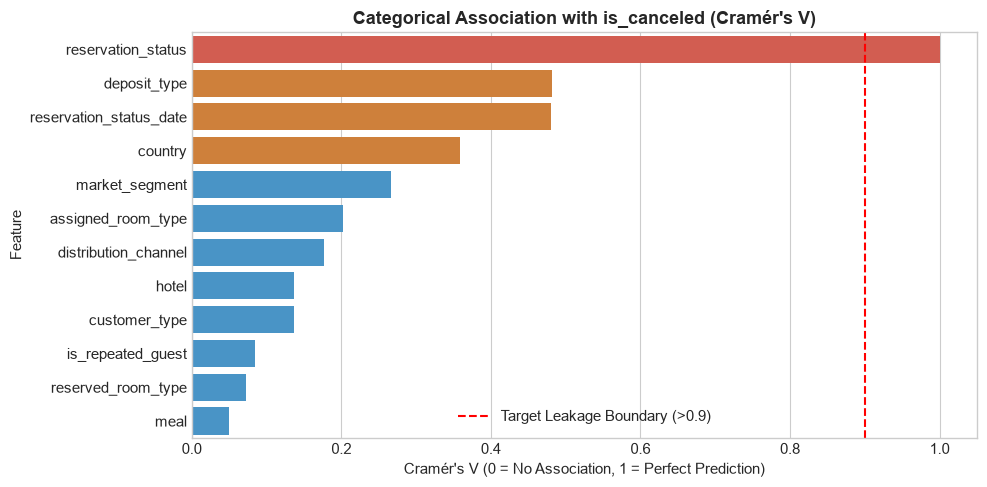

In [3]:
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    rcorr = r - ((r - 1) ** 2) / (n - 1)
    kcorr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

# Compute association of each categorical feature with is_canceled
assoc_records = []
all_cats_to_test = cat_cols + status_cols

for col in all_cats_to_test:
    # Filter missing for computation
    sub_df = df[[col, "is_canceled"]].dropna()
    cv = cramers_v(sub_df[col], sub_df["is_canceled"])
    assoc_records.append({
        "Feature": col,
        "Cramer_V": round(cv, 4),
        "Unique_Levels": df[col].nunique(),
        "Risk_Category": "CRITICAL LEAKAGE" if cv > 0.9 else ("HIGH CORRELATION" if cv > 0.3 else "MODERATE/LOW")
    })

assoc_df = pd.DataFrame(assoc_records).sort_values(by="Cramer_V", ascending=False)
print("Categorical Association with Target (is_canceled):")
display(assoc_df)

# Plot association
plt.figure(figsize=(10, 5))
colors = ["#e74c3c" if r == "CRITICAL LEAKAGE" else ("#e67e22" if r == "HIGH CORRELATION" else "#3498db")
          for r in assoc_df["Risk_Category"]]
sns.barplot(data=assoc_df, x="Cramer_V", y="Feature", palette=colors)
plt.title("Categorical Association with is_canceled (Cramér's V)", fontweight="bold")
plt.xlabel("Cramér's V (0 = No Association, 1 = Perfect Prediction)")
plt.axvline(0.9, color="red", linestyle="--", label="Target Leakage Boundary (>0.9)")
plt.legend()
plt.tight_layout()
plt.show()

## 3. Deep Dive: Target Leakage Audit

### Critical Finding 1: `reservation_status` (Cramér's V = 1.000)
`reservation_status` describes the terminal state of the reservation (`Check-Out`, `Canceled`, or `No-Show`). This is 100% target leakage.

In [4]:
crosstab_status = pd.crosstab(df["reservation_status"], df["is_canceled"], margins=True)
crosstab_status_pct = pd.crosstab(df["reservation_status"], df["is_canceled"], normalize="index") * 100

print("Crosstab: reservation_status vs is_canceled:")
display(crosstab_status)
print("\nPercentage Breakdown (%):")
display(crosstab_status_pct.round(2))

Crosstab: reservation_status vs is_canceled:


is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390



Percentage Breakdown (%):


is_canceled,0,1
reservation_status,,
Canceled,0.0,100.0
Check-Out,100.0,0.0
No-Show,0.0,100.0


### Critical Finding 2: `deposit_type` (Cramér's V = 0.478)
In intuition, a non-refundable deposit should *deter* cancellations. However, in this dataset:
- `Non Refund` has a cancellation rate of **~99.36%**!
- `No Deposit` has a cancellation rate of **~28.38%**!
- `Refundable` has a cancellation rate of **~22.22%**!

This counter-intuitive relationship occurs because hotels used non-refundable deposits selectively for high-risk tour groups or high-cancellation wholesale segments. We analyze this distribution below.

Cancellation Rate by Deposit Type:


,deposit_type,Total_Bookings,Cancellations,Cancellation_Rate
0,No Deposit,104641,29694,28.38
1,Non Refund,14587,14494,99.36
2,Refundable,162,36,22.22


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\3003017764.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=deposit_summary, x="deposit_type", y="Cancellation_Rate", palette="Reds_r", ax=axes[1])


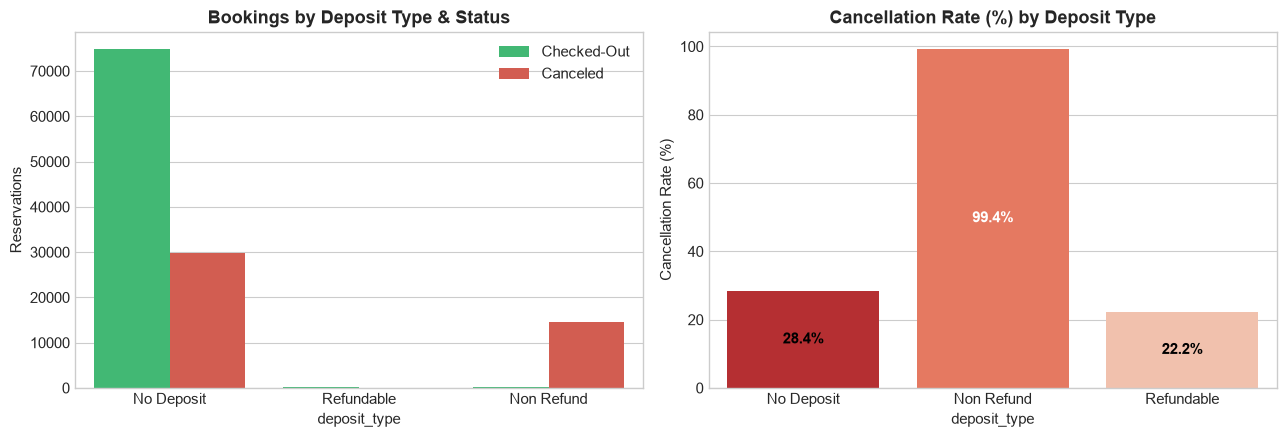

In [5]:
deposit_summary = df.groupby("deposit_type")["is_canceled"].agg(
    Total_Bookings="count",
    Cancellations="sum",
    Cancellation_Rate=lambda x: round((x.mean() * 100), 2)
).reset_index()

print("Cancellation Rate by Deposit Type:")
display(deposit_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(data=df, x="deposit_type", hue="is_canceled", palette=["#2ecc71", "#e74c3c"], ax=axes[0])
axes[0].set_title("Bookings by Deposit Type & Status", fontweight="bold")
axes[0].set_ylabel("Reservations")
axes[0].legend(["Checked-Out", "Canceled"])

sns.barplot(data=deposit_summary, x="deposit_type", y="Cancellation_Rate", palette="Reds_r", ax=axes[1])
axes[1].set_title("Cancellation Rate (%) by Deposit Type", fontweight="bold")
axes[1].set_ylabel("Cancellation Rate (%)")
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                     ha="center", va="center", color="white" if p.get_height() > 50 else "black", fontweight="bold")

plt.tight_layout()
plt.show()

### Critical Finding 3: `assigned_room_type` vs `reserved_room_type` (Post-Booking Leakage)
At booking time, the guest selects `reserved_room_type`. The `assigned_room_type` is determined at check-in or when the room is allocated. 
When `reserved_room_type != assigned_room_type`, it indicates a room reassignment or upgrade, which happens at the property. We verify its relationship with cancellation.

Cancellation Rate: Room Change vs Same Room:


,room_type_changed,Total_Bookings,Cancellations,Cancellation_Rate,Label
0,0,104473,43422,41.56,Same Room Assigned
1,1,14917,802,5.38,Room Type Changed / Upgraded


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\3645965462.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=room_change_summary, x="Label", y="Cancellation_Rate", palette=["#e74c3c", "#2ecc71"])


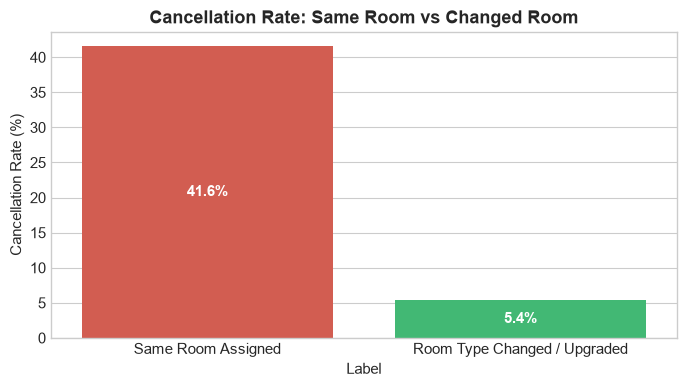

In [6]:
df["room_type_changed"] = (df["reserved_room_type"] != df["assigned_room_type"]).astype(int)

room_change_summary = df.groupby("room_type_changed")["is_canceled"].agg(
    Total_Bookings="count",
    Cancellations="sum",
    Cancellation_Rate=lambda x: round((x.mean() * 100), 2)
).reset_index()
room_change_summary["Label"] = ["Same Room Assigned", "Room Type Changed / Upgraded"]

print("Cancellation Rate: Room Change vs Same Room:")
display(room_change_summary)

plt.figure(figsize=(7, 4))
sns.barplot(data=room_change_summary, x="Label", y="Cancellation_Rate", palette=["#e74c3c", "#2ecc71"])
plt.title("Cancellation Rate: Same Room vs Changed Room", fontweight="bold")
plt.ylabel("Cancellation Rate (%)")
for p in plt.gca().patches:
    plt.gca().annotate(f"{p.get_height():.1f}%", (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                       ha="center", va="center", color="white", fontweight="bold")
plt.tight_layout()
plt.show()

## 4. Distributions of Legitimate Booking-Time Categoricals

We now review the legitimate booking-time categorical features: `hotel`, `market_segment`, `distribution_channel`, `customer_type`, `meal`, and top countries.

C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=axes[i, 0], palette="Blues_r")


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=axes[i, 1], palette="magma")
C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=axes[i, 0], palette="Blues_r")


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=axes[i, 1], palette="magma")


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=axes[i, 0], palette="Blues_r")
C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=axes[i, 1], palette="magma")


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=axes[i, 0], palette="Blues_r")


C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=axes[i, 1], palette="magma")
C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x=col, order=order, ax=axes[i, 0], palette="Blues_r")
C:\Users\joshu\AppData\Local\Temp\ipykernel_10164\2663567403.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rates.index, y=rates.values, ax=axes[i, 1], palette="magma")


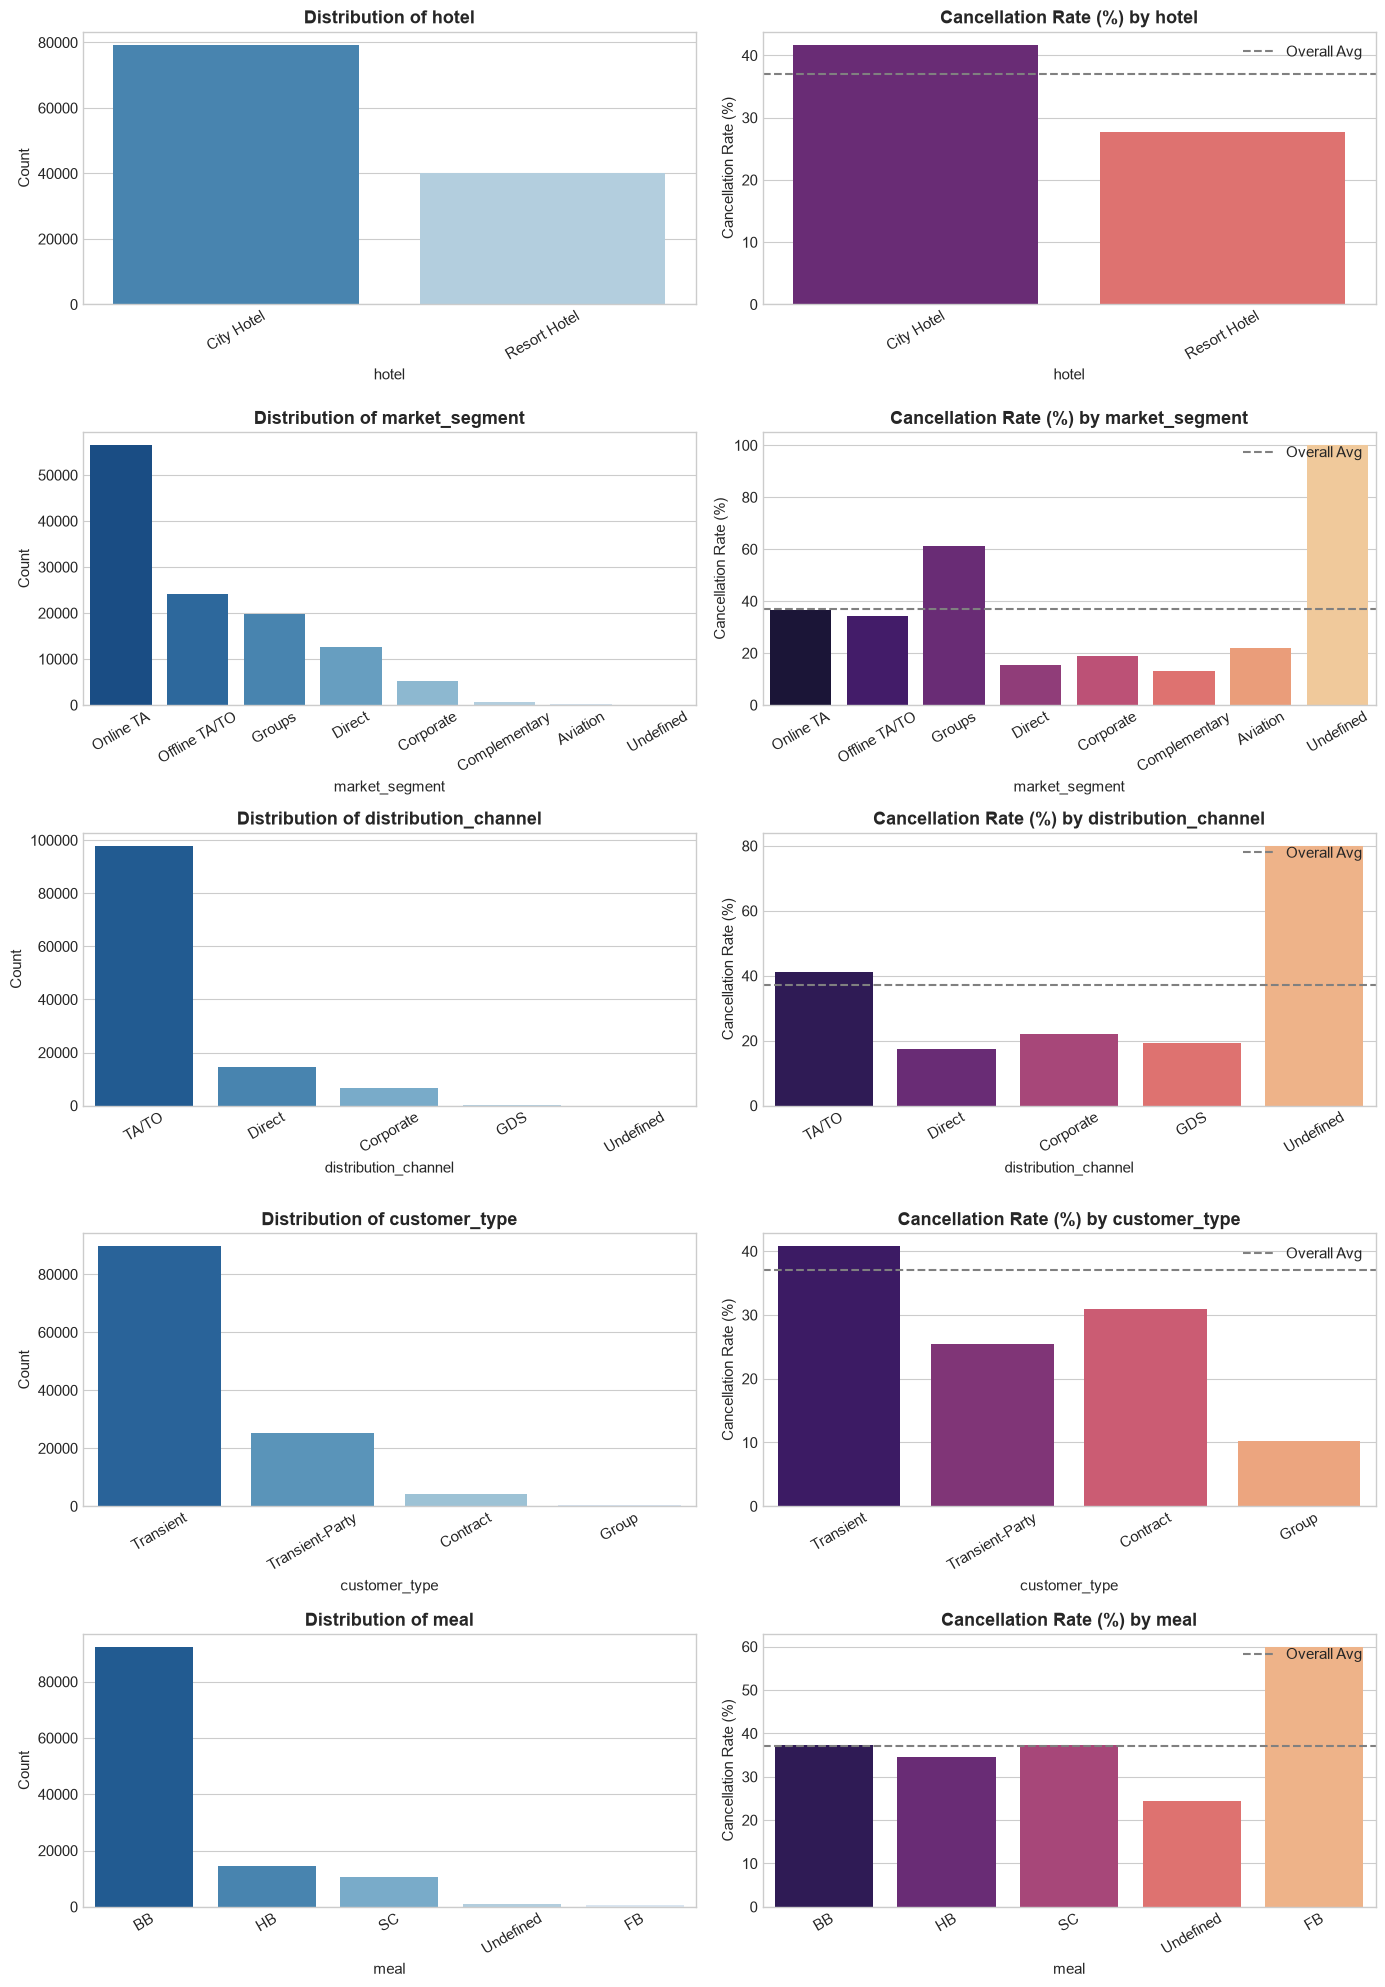

In [7]:
legit_cats = ["hotel", "market_segment", "distribution_channel", "customer_type", "meal"]

fig, axes = plt.subplots(len(legit_cats), 2, figsize=(14, 4 * len(legit_cats)))

for i, col in enumerate(legit_cats):
    # Left: Frequency count
    order = df[col].value_counts().index
    sns.countplot(data=df, x=col, order=order, ax=axes[i, 0], palette="Blues_r")
    axes[i, 0].set_title(f"Distribution of {col}", fontweight="bold")
    axes[i, 0].tick_params(axis="x", rotation=30)
    axes[i, 0].set_ylabel("Count")

    # Right: Cancellation Rate
    rates = df.groupby(col)["is_canceled"].mean().loc[order] * 100
    sns.barplot(x=rates.index, y=rates.values, ax=axes[i, 1], palette="magma")
    axes[i, 1].set_title(f"Cancellation Rate (%) by {col}", fontweight="bold")
    axes[i, 1].tick_params(axis="x", rotation=30)
    axes[i, 1].set_ylabel("Cancellation Rate (%)")
    axes[i, 1].axhline(df["is_canceled"].mean() * 100, color="gray", linestyle="--", label="Overall Avg")
    axes[i, 1].legend(loc="upper right")

plt.tight_layout()
plt.show()

### Geographic Distribution (`country` Top 10)
`country` has 177 distinct country codes. Below are the top 10 countries by volume and their corresponding cancellation rates.

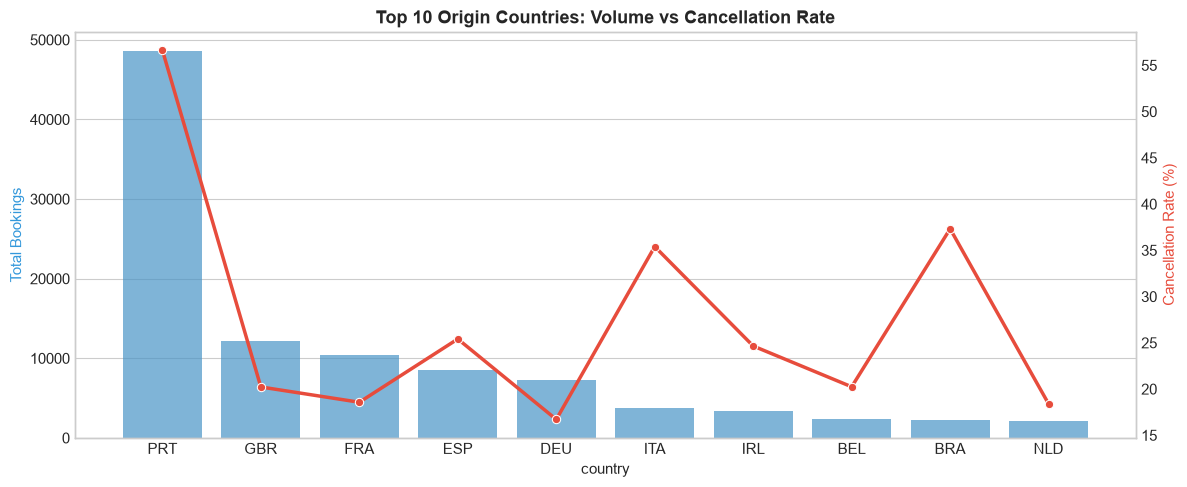

In [8]:
top_countries = df["country"].value_counts().head(10).index

country_df = df[df["country"].isin(top_countries)].groupby("country").agg(
    Total_Bookings=("is_canceled", "count"),
    Cancellation_Rate=("is_canceled", lambda x: round(x.mean() * 100, 2))
).loc[top_countries].reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
ax2 = ax1.twinx()

sns.barplot(data=country_df, x="country", y="Total_Bookings", ax=ax1, color="#3498db", alpha=0.7)
sns.lineplot(data=country_df, x="country", y="Cancellation_Rate", ax=ax2, color="#e74c3c", marker="o", linewidth=2.5)

ax1.set_title("Top 10 Origin Countries: Volume vs Cancellation Rate", fontweight="bold")
ax1.set_ylabel("Total Bookings", color="#3498db")
ax2.set_ylabel("Cancellation Rate (%)", color="#e74c3c")
ax2.grid(False)
plt.tight_layout()
plt.show()

## 5. Key Takeaways & Leakage Mitigation Rules

1. **Target Leakage Exclusion (Mandatory):**
   - **`reservation_status`:** Must be dropped entirely from the predictive pipeline (Cramér's V = 1.000).
   - **`reservation_status_date`:** Must be dropped entirely; it reflects the cancellation or checkout event timestamp.
2. **Post-Booking State Exclusion:**
   - **`assigned_room_type`:** Must be excluded at booking time because rooms are assigned upon arrival/check-in. Only `reserved_room_type` is valid for initial booking prediction.
3. **High-Correlation Domain Features:**
   - **`deposit_type`:** `Non Refund` has a ~99.4% cancellation rate. This is not leakage but an artifact of hotel policy imposing non-refundable terms on volatile group blocks.
   - **`market_segment`:** `Groups` has ~61.1% cancellation rate vs `Direct` with ~15.3%.
   - **`hotel`:** `City Hotel` exhibits significantly higher cancellation (~41.7%) than `Resort Hotel` (~27.8%).